# Análisis exploratorio de los datos de ordeño
## Hecho por: Yael Charles Marin

EDA del dataset anonimizado integrado. Se revisan calidad, formatos, cobertura,
distribuciones, mediciones por cuarto, incidentes y asociaciones exploratorias.
Las cifras y observaciones se recalculan al ejecutar todas las celdas.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"figure.figsize": (11, 5), "figure.dpi": 110})
pd.set_option("display.max_columns", 45)
pd.set_option("display.max_rows", 45)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

raiz = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "Data" / "dataset_vacas_anonimo.csv").is_file()), None)
if raiz is None:
    raise FileNotFoundError("No se encontró Data/dataset_vacas_anonimo.csv desde el directorio actual.")
ruta = raiz / "Data" / "dataset_vacas_anonimo.csv"
df_original = pd.read_csv(ruta, encoding="utf-8", low_memory=False,
                          dtype={"id_vaca": "string", "misc_eo_po": "string"})
print(f"Archivo: {ruta.name} | Filas: {len(df_original):,} | Columnas: {df_original.shape[1]}")
display(df_original.head())

# El formato identifica la representación recibida, no la procedencia garantizada.
formato_original = pd.Series("Otro", index=df_original.index, dtype="string")
texto_fecha = df_original["main_hora_de_inicio"].astype("string")
formato_original.loc[texto_fecha.str.match(r"^\d{4}-\d{2}-\d{2}", na=False)] = "ISO"
formato_original.loc[texto_fecha.str.match(r"^\d{2}/\d{2}/\d{4}", na=False)] = "Día/mes/año"
display(df_original.assign(formato_fecha=formato_original).groupby("formato_fecha").agg(
    registros=("id_vaca", "size"), vacas=("id_vaca", "nunique"),
    accion_disponible=("main_accion", "count"), produccion_disponible=("main_produccion_kg", "count")))

Archivo: dataset_vacas_anonimo.csv | Filas: 286,217 | Columnas: 44


,id_vaca,main_hora_de_inicio,main_accion,main_duracion_mm_ss,main_produccion_kg,estado_numero_de_ordeno,estado_rcs_1000_celulas_ml,estado_patada,estado_incompleto,estado_pezones_no_encontrados,estado_amd_ubre,estado_amd_pezon,media_de_los_flujos_kg_min_di,media_de_los_flujos_kg_min_dd,media_de_los_flujos_kg_min_ti,media_de_los_flujos_kg_min_td,sangre_ppm_di,sangre_ppm_dd,sangre_ppm_ti,sangre_ppm_td,conductividad_ms_cm_di,conductividad_ms_cm_dd,conductividad_ms_cm_ti,conductividad_ms_cm_td,misc_eo_po,misc_usuario,misc_destino_leche,misc_razon_de_la_desviacion,flujos_maximos_kg_min_di,flujos_maximos_kg_min_dd,flujos_maximos_kg_min_ti,flujos_maximos_kg_min_td,producciones_kg_di,producciones_kg_dd,producciones_kg_ti,producciones_kg_td,main_intervalo_de_ordeno_hh_mm,contadores_monitorizacion_vaca_ubre,contadores_monitorizacion_vaca_di,contadores_monitorizacion_vaca_dd,contadores_monitorizacion_vaca_ti,contadores_monitorizacion_vaca_td,misc_programa_de_lavado,estado_mdi
0,9e261839,01/03/2025 05:37 a. m.,Ordeño,09:58,23.960,1.000,NaN,NaN,NaN,NaN,1.000,NaN,1.260,1.740,1.860,1.620,0.000,0.000,0.000,0.000,4.920,5.160,5.480,5.210,ff24d34e,NaN,Tanque,NaN,1.740,2.160,2.400,2.100,6.110,5.560,3.330,8.960,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,9e261839,01/03/2025 07:15 p. m.,Ordeño,06:51,17.200,2.000,NaN,DI,NaN,NaN,1.000,NaN,1.140,1.800,2.040,1.740,0.000,0.000,0.000,0.000,4.580,4.840,5.260,4.880,ff24d34e,NaN,Tanque,NaN,2.100,2.340,2.520,2.280,3.230,4.860,2.690,6.420,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,9e261839,02/03/2025 02:24 a. m.,Ordeño,07:23,11.130,1.000,NaN,NaN,NaN,NaN,1.000,TI,1.200,1.440,1.740,1.440,0.000,0.000,0.000,0.000,4.260,4.380,5.000,4.520,ff24d34e,NaN,Tanque,NaN,1.680,1.980,2.340,1.920,4.400,2.430,1.150,3.150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,9e261839,02/03/2025 07:51 p. m.,Ordeño,08:29,20.640,2.000,NaN,NaN,NaN,NaN,1.000,NaN,1.200,1.680,1.920,1.680,0.000,0.000,0.000,0.000,4.360,4.770,5.010,4.820,ff24d34e,NaN,Tanque,NaN,2.100,2.220,2.520,2.400,5.720,4.880,3.100,6.940,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,9e261839,03/03/2025 06:00 a. m.,Ordeño,05:05,9.590,1.000,NaN,NaN,NaN,NaN,1.000,NaN,1.140,1.620,1.800,1.500,0.000,0.000,0.000,0.000,4.130,4.420,4.360,4.440,ff24d34e,NaN,Tanque,NaN,1.800,2.100,2.280,1.980,2.690,2.410,1.440,3.050,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,registros,vacas,accion_disponible,produccion_disponible
formato_fecha,,,,
Día/mes/año,7249,34,7249,7016
ISO,278968,201,0,278968


## 1. Inventario y calidad de los datos

La tabla resume tipos, valores disponibles y diversidad de cada columna. Los indicadores de incidentes contienen etiquetas de cuartos y nulos; un campo vacío no se interpreta automáticamente como ausencia de un incidente.

In [2]:
## Tipo de datos, nulos y valores distintos

perfil = pd.DataFrame({
    "tipo": df_original.dtypes.astype(str),
    "no_nulos": df_original.notna().sum(),
    "nulos": df_original.isna().sum(),
    "nulos_pct": df_original.isna().mean().mul(100),
    "valores_distintos": df_original.nunique(dropna=True),
})
display(perfil)


,tipo,no_nulos,nulos,nulos_pct,valores_distintos
id_vaca,string,286217,0,0.000,207
main_hora_de_inicio,str,286217,0,0.000,285792
main_accion,str,7249,278968,97.467,3
main_duracion_mm_ss,str,286217,0,0.000,2126
main_produccion_kg,float64,285984,233,0.081,3698
estado_numero_de_ordeno,float64,285984,233,0.081,6
estado_rcs_1000_celulas_ml,float64,0,286217,100.000,0
estado_patada,str,46188,240029,83.863,15
estado_incompleto,str,34419,251798,87.975,15
estado_pezones_no_encontrados,str,34175,252042,88.060,15


En esta tabla podemos ver un resumen de todas las columnas con las que contamos, su tipo de datos, valores nulos y no nulos, porcentaje de nulos y la cantidad de valores distintos en todo el dataset.

Se encuentran cosas muy curiosas como que en los 280 mil datos solo existe un valor de misc_programa_de_lavado y misc_usuario que sean diferente, la columna de misc_eo_po se refiere a las maquinas de ordeño y muestra que tiene cero valores nulos y 4 valores diferentes, lo que resulta extraño considerando que en la visita del caetec solo se observaron 3 maquinas.

Examinando en los datos se encontró un registró sin datos de la vaca y que parece ser un error de datos correspondiente a 1 registro en las vacas: 8753 y 6232, esto se relaciona con los 2 unicos registros de usuario que tenemos en el dataset, que también forman parte de este posible error al registrar.

En la columna de main_accion aparecen muchisimos valores nulos, que corresponden a los datos de 2026, porque en esta no existe esta columna, por ello es que son nulos.

In [3]:
## Estadistica descriptiva de las variables numéricas

display(df_original.select_dtypes(include="number").describe().T)

,count,mean,std,min,25%,50%,75%,max
main_produccion_kg,"285,984.000",14.795,5.339,0.000,11.050,14.270,18.080,78.170
estado_numero_de_ordeno,"285,984.000",1.837,0.844,1.000,1.000,2.000,2.000,6.000
estado_rcs_1000_celulas_ml,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
estado_amd_ubre,"285,984.000",0.123,0.328,0.000,0.000,0.000,0.000,1.000
media_de_los_flujos_kg_min_di,"280,758.000",1.148,0.399,0.000,0.900,1.140,1.380,4.980
media_de_los_flujos_kg_min_dd,"278,706.000",1.177,0.389,0.000,0.960,1.200,1.440,4.860
media_de_los_flujos_kg_min_ti,"281,480.000",1.166,0.489,0.000,0.900,1.140,1.440,5.100
media_de_los_flujos_kg_min_td,"274,920.000",1.124,0.467,0.000,0.840,1.140,1.440,4.980
sangre_ppm_di,"280,758.000",34.295,347.313,0.000,0.000,0.000,0.000,"8,000.000"
sangre_ppm_dd,"278,706.000",17.084,174.102,0.000,0.000,0.000,0.000,"7,999.000"


De la estadistica descriptiva obtenemos que en promedio por ordeño se obtienen aproximadamente 15kg de leche con una desviación estandar cercana a 5 kg, su valor máximo es 78 kg y su minimo es de 0, que puede deberse a un ordeño incompleto, error en la medición, etc.

Se observa que la mayoría de columnas tienen valores de decenas o centenas, mientras que las columnas de sangre en partes por millon de los cuartos tienen valores de miles, habría que investigar que tan relevante son un promedio de 10 ppm de sangre por ordeño, pero también ajustar esta columna si se utilizará con el modelo.

Finalmente las producciones de los cuartos de leche, son relativamente cercanas entre si, teniendo un valor promedio superior el cuarto trasero izquierdo, pero el mayor valor registrado se lo lleva el cuarto trasero derecho.

In [4]:
print("Columnas completamente vacías:", perfil.index[perfil.no_nulos.eq(0)].tolist())

acciones = df_original["main_accion"].fillna("Sin acción informada").value_counts().rename("eventos").to_frame()
acciones["porcentaje"] = acciones.eventos.div(len(df_original)).mul(100)
display(acciones)


Columnas completamente vacías: ['estado_rcs_1000_celulas_ml']


,eventos,porcentaje
main_accion,,
Sin acción informada,278968,97.467
Ordeño,7016,2.451
Rechazada,172,0.060
Echada sin ordeñar,61,0.021


De la tabla de eventos podemos notar que la mayoría corresponden a sin acción informada, este valor sale de los registros de datos de 2026 los cuales no tienen la columna de main_accion, los valores restantes corresponden unicamente a los datos de 2025, se observa dentro de este intervalo que rechazada y echada sin ordeñar ocurren muy pocas de las veces.

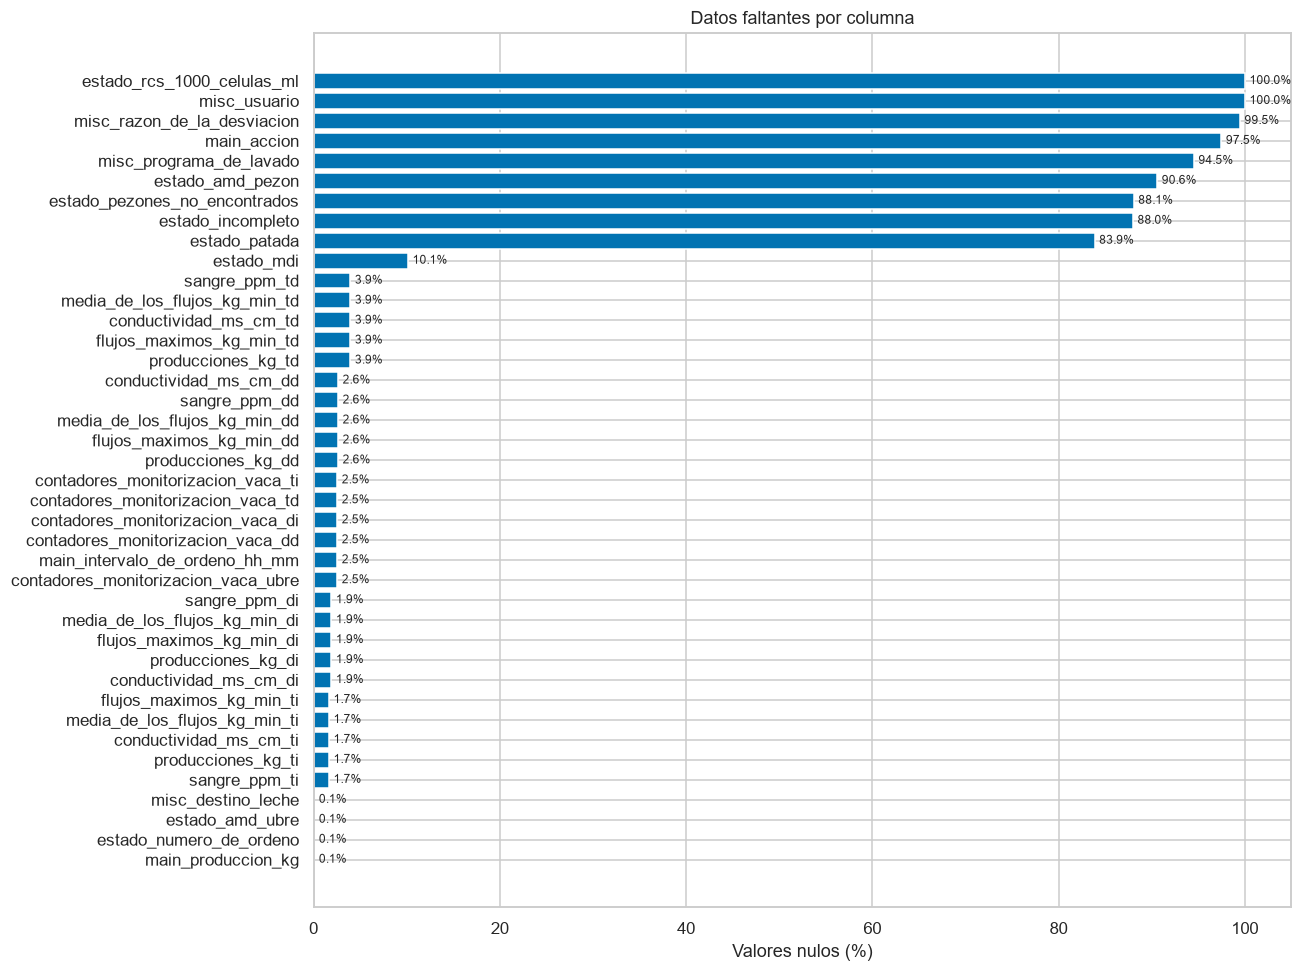

In [5]:
nulos = perfil.loc[perfil.nulos.gt(0)].sort_values("nulos_pct")
fig, ax = plt.subplots(figsize=(12, 9))
ax.barh(nulos.index, nulos.nulos_pct)
ax.set(xlabel="Valores nulos (%)", title="Datos faltantes por columna", xlim=(0, 105))
for i, v in enumerate(nulos.nulos_pct):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=8)
plt.tight_layout()
plt.show()

En esta gráfica se muestra el porcentaje de valores nulos de forma visual, las primeras dos columnas tienen un 100% de datos nulos, mientras que razón de la desviacion tiene un porcentaje muy cercano a este, de la misma forma que main_accion por lo que ya hemos mencionado anteriormente y algunas otras columnas también como estado incompleto, patada y pezones no encontrados, ya que esto indica que el ordeño ocurre con normalidad en la mayoria de los casos.

### Duplicados exactos y coincidencias de identificadores

Se distinguen filas idénticas de coincidencias en `(id_vaca, main_hora_de_inicio)`.
Una hora registrada al minuto puede agrupar eventos distintos. Primero se retiran
copias exactas; después de convertir fechas y duraciones se aplica una regla
adicional, explícita y configurable para coincidencias entre exportaciones.

In [6]:
clave = ["id_vaca", "main_hora_de_inicio"]
duplicados_exactos = df_original.duplicated()
coincidencias_clave = df_original.duplicated(clave, keep=False)

print(f"Copias exactas adicionales: {duplicados_exactos.sum()}")
print(f"Filas involucradas en duplicados exactos: {df_original.duplicated(keep=False).sum()}")
print(f"Coincidencias adicionales en vaca y hora: {df_original.duplicated(clave).sum()}")

display(df_original.loc[df_original.duplicated(keep=False),
    clave + ["main_accion", "main_duracion_mm_ss", "main_produccion_kg"]].head(30))

display(df_original.loc[coincidencias_clave,
    clave + ["main_accion", "main_duracion_mm_ss", "main_produccion_kg"]]
    .sort_values(clave).head(30))

df = df_original.drop_duplicates().copy()
df["formato_fecha"] = formato_original.loc[df.index]
print(f"Base exploratoria después de quitar copias exactas: {len(df):,} eventos")

Copias exactas adicionales: 2
Filas involucradas en duplicados exactos: 4
Coincidencias adicionales en vaca y hora: 25


,id_vaca,main_hora_de_inicio,main_accion,main_duracion_mm_ss,main_produccion_kg
541,cfbafffc,06/05/2025 02:46 p. m.,Rechazada,00:00,NaN
542,cfbafffc,06/05/2025 02:46 p. m.,Rechazada,00:00,NaN
3125,78f46d32,28/05/2025 07:30 a. m.,Rechazada,00:00,NaN
3126,78f46d32,28/05/2025 07:30 a. m.,Rechazada,00:00,NaN


,id_vaca,main_hora_de_inicio,main_accion,main_duracion_mm_ss,main_produccion_kg
2118,01784b0a,16/03/2025 06:31 a. m.,Ordeño,08:06,16.570
2119,01784b0a,16/03/2025 06:31 a. m.,Echada sin ordeñar,08:05,NaN
5004,080047a3,16/03/2025 03:37 a. m.,Ordeño,07:13,23.550
5005,080047a3,16/03/2025 03:37 a. m.,Echada sin ordeñar,07:13,NaN
3580,2a319e33,16/03/2025 03:09 a. m.,Ordeño,07:29,11.280
3581,2a319e33,16/03/2025 03:09 a. m.,Echada sin ordeñar,07:28,NaN
4972,2a4248d4,16/07/2025 03:20 p. m.,Ordeño,00:55,0.000
4973,2a4248d4,16/07/2025 03:20 p. m.,Rechazada,00:54,NaN
4974,2a4248d4,16/07/2025 03:23 p. m.,Ordeño,09:55,1.230
4975,2a4248d4,16/07/2025 03:23 p. m.,Rechazada,09:55,NaN


Base exploratoria después de quitar copias exactas: 286,215 eventos


La primera tabla muestra dos duplicados exactos de eventos de ordeño rechazado a la misma hora y misma vaca por lo que lo más probable es que se tarde de un error.

La siguiente tabla muestra pares de ordeños que ocurrieron el mismo día para la misma vaca, estos parecen ser errores de la maquina que haya registrado un segundo evento con motivo de echada sin ordeñar después de haberla ordeñado y donde si se registró su producción, además existe un caso donde 1 par tiene ambos eventos como rechazada, en ese caso se sugiere borrar una puesto que ambos registros tienen la misma información.

## 2. Fechas, duración y validaciones de coherencia



In [7]:
def convertir_fechas(serie):
    texto = (serie.astype("string").str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.replace(r"(?i)a\.\s*m\.", "AM", regex=True)
        .str.replace(r"(?i)p\.\s*m\.", "PM", regex=True))
    resultado = pd.Series(pd.NaT, index=serie.index, dtype="datetime64[ns]")
    formatos = ["%d/%m/%Y %I:%M %p", "%d/%m/%Y %I:%M:%S %p",
                "%d/%m/%Y %H:%M", "%d/%m/%Y %H:%M:%S",
                "%Y-%m-%d %H:%M:%S", "%Y-%m-%d %H:%M:%S.%f",
                "%Y-%m-%dT%H:%M:%S"]
    for formato in formatos:
        pendientes = resultado.isna() & texto.notna()
        resultado.loc[pendientes] = pd.to_datetime(
            texto.loc[pendientes], format=formato, errors="coerce")
    return resultado


def convertir_tiempo(serie, dos_partes="mm:ss", excel=False):
    """Devuelve segundos; valida minutos/segundos y conserva horas > 24."""
    texto = serie.astype("string").str.strip()
    resultado = pd.Series(np.nan, index=serie.index, dtype=float)
    tres = texto.str.extract(r"^(\d+):([0-5]\d):([0-5]\d)$").astype(float)
    resultado = tres[0] * 3600 + tres[1] * 60 + tres[2]
    dos = texto.str.extract(r"^(\d+):([0-5]\d)$").astype(float)
    factor = 60 if dos_partes == "mm:ss" else 3600
    resultado = resultado.fillna(dos[0] * factor + dos[1] * factor / 60)
    if excel:
        fechas_excel = pd.to_datetime(texto.where(texto.str.match(r"^1900-", na=False)),
                                     format="%Y-%m-%d %H:%M:%S", errors="coerce")
        serial = (fechas_excel - pd.Timestamp("1899-12-31")).dt.total_seconds()
        serial += fechas_excel.ge(pd.Timestamp("1900-03-01")).astype(int) * 86400
        resultado = resultado.fillna(serial)
    return resultado


df["fecha_hora"] = convertir_fechas(df["main_hora_de_inicio"])
df["duracion_min"] = convertir_tiempo(df["main_duracion_mm_ss"]) / 60
df["intervalo_declarado_h"] = convertir_tiempo(
    df["main_intervalo_de_ordeno_hh_mm"], dos_partes="hh:mm", excel=True) / 3600
df["fecha"] = df.fecha_hora.dt.normalize()
df["hora"] = df.fecha_hora.dt.hour
df["mes"] = df.fecha_hora.dt.to_period("M")
df["fecha_minuto"] = df.fecha_hora.dt.floor("min")

conversiones = [("main_hora_de_inicio", "fecha_hora"),
               ("main_duracion_mm_ss", "duracion_min"),
               ("main_intervalo_de_ordeno_hh_mm", "intervalo_declarado_h")]
errores_conversion = []
for original, convertido in conversiones:
    presentes = df[original].notna() & df[original].astype("string").str.strip().ne("")
    fallos = presentes & df[convertido].isna()
    errores_conversion.append({"columna": original, "ausentes": int((~presentes).sum()),
                               "convertidos": int(df[convertido].notna().sum()),
                               "no_interpretables": int(fallos.sum())})
    if fallos.any():
        display(df.loc[fallos, ["id_vaca", original]].head(10))
display(pd.DataFrame(errores_conversion).set_index("columna"))
print(f"Periodo: {df.fecha_hora.min()} a {df.fecha_hora.max()}")
print(f"Vacas: {df.id_vaca.nunique()} | Códigos de equipo: {df.misc_eo_po.nunique()}")

# Inclusión explícita: no rellenamos main_accion ni equiparamos sus nulos a una etiqueta.
accion_ordeno = df["main_accion"].eq("Ordeño")
accion_ausente = df["main_accion"].isna() | df["main_accion"].astype("string").str.strip().eq("").fillna(False)
compatible = accion_ausente & df["main_produccion_kg"].notna()
df["criterio_inclusion"] = "Fuera de la base de ordeños"
df.loc[accion_ordeno, "criterio_inclusion"] = "Ordeño explícito"
df.loc[compatible, "criterio_inclusion"] = "Producción con acción no informada"

# Coincidencias entre formatos: correspondencia uno a uno, mismos datos compartidos.
# Conductividad: tolerancia de 0.005 mS/cm porque el bloque antiguo redondea a 2 decimales.
claves_exportacion = ["id_vaca", "fecha_minuto", "misc_eo_po", "main_produccion_kg", "duracion_min"]
antiguos = df.loc[df.formato_fecha.eq("Día/mes/año") & accion_ordeno].dropna(subset=claves_exportacion)
nuevos = df.loc[df.formato_fecha.eq("ISO") & compatible].dropna(subset=claves_exportacion)
pares = antiguos.reset_index(names="fila_antigua").merge(
    nuevos.reset_index(names="fila_nueva"), on=claves_exportacion, suffixes=("_ant", "_nuevo"))
coinciden = (~pares.fila_antigua.duplicated(keep=False) & ~pares.fila_nueva.duplicated(keep=False))
columnas_compartidas = [c for c in df_original.columns
    if c not in claves_exportacion + ["main_hora_de_inicio", "main_duracion_mm_ss", "main_accion"]
    and antiguos[c].notna().any() and nuevos[c].notna().any()]
for columna in columnas_compartidas:
    a, b = pares[columna + "_ant"], pares[columna + "_nuevo"]
    iguales = a.eq(b).fillna(False) | (a.isna() & b.isna())
    if columna.startswith("conductividad_"):
        iguales |= a.sub(b).abs().le(0.005 + 1e-9)
    coinciden &= iguales
pares_exportacion = pares.loc[coinciden, ["fila_antigua", "fila_nueva"] + claves_exportacion].copy()
df["coincidencia_exportacion"] = df.index.isin(pares_exportacion.fila_antigua)

# Cambiar a False permite repetir el EDA conservando ambas exportaciones.
EXCLUIR_COINCIDENCIAS_EXPORTACION = True
base_inclusion = accion_ordeno | compatible
ordenos_antes = df.loc[base_inclusion].copy()
excluir = df.coincidencia_exportacion & EXCLUIR_COINCIDENCIAS_EXPORTACION
ordenos = df.loc[base_inclusion & ~excluir].copy()
sensibilidad = pd.DataFrame({
    "incluyendo_coincidencias": [len(ordenos_antes), ordenos_antes.main_produccion_kg.sum(), ordenos_antes.main_produccion_kg.mean()],
    "base_seleccionada": [len(ordenos), ordenos.main_produccion_kg.sum(), ordenos.main_produccion_kg.mean()],
}, index=["registros", "produccion_total_kg", "produccion_media_kg"])
display(sensibilidad)
display(ordenos.criterio_inclusion.value_counts().to_frame("registros"))
print(f"Pares entre exportaciones que cumplen la regla: {len(pares_exportacion):,}.")
print("Se conserva la fila ISO con precisión de segundos; las filas originales permanecen en df_original y df.")
display(pares_exportacion.head(10))

cuartos = ["di", "dd", "ti", "td"]
columnas_cuartos = [f"producciones_kg_{q}" for q in cuartos]
ordenos["suma_cuartos_kg"] = ordenos[columnas_cuartos].sum(axis=1, min_count=4)
ordenos["diferencia_total_kg"] = ordenos.main_produccion_kg - ordenos.suma_cuartos_kg
mediciones = [c for c in df_original.select_dtypes(include="number").columns
              if c.startswith(("main_produccion", "media_de_los_flujos", "sangre_",
                               "conductividad_", "flujos_maximos_", "producciones_"))]
validaciones = pd.Series({
    "registros incluidos sin producción": ordenos.main_produccion_kg.isna().sum(),
    "registros incluidos con producción cero": ordenos.main_produccion_kg.eq(0).sum(),
    "registros incluidos con duración cero": ordenos.duracion_min.eq(0).sum(),
    "filas con alguna medición negativa": df[mediciones].lt(0).any(axis=1).sum(),
    "registros con cuatro producciones disponibles": ordenos.suma_cuartos_kg.notna().sum(),
    "diferencia total vs suma > 0.05 kg": ordenos.diferencia_total_kg.abs().gt(0.05 + 1e-9).sum(),
})
display(validaciones.to_frame("filas"))


,ausentes,convertidos,no_interpretables
columna,,,
main_hora_de_inicio,0,286215,0
main_duracion_mm_ss,0,286215,0
main_intervalo_de_ordeno_hh_mm,7247,278968,0


Periodo: 2022-07-13 00:05:28 a 2026-01-28 11:47:54
Vacas: 207 | Códigos de equipo: 4


,incluyendo_coincidencias,base_seleccionada
registros,"285,984.000","280,699.000"
produccion_total_kg,"4,231,077.324","4,159,103.994"
produccion_media_kg,14.795,14.817


,registros
criterio_inclusion,
Producción con acción no informada,278968
Ordeño explícito,1731


Pares entre exportaciones que cumplen la regla: 5,285.
Se conserva la fila ISO con precisión de segundos; las filas originales permanecen en df_original y df.


,fila_antigua,fila_nueva,id_vaca,fecha_minuto,misc_eo_po,main_produccion_kg,duracion_min
0,259,13990,dc716df4,2025-03-01 09:00:00,ff24d34e,15.300,6.700
1,260,13989,dc716df4,2025-03-01 23:06:00,ff24d34e,19.470,7.750
2,261,13988,dc716df4,2025-03-02 10:37:00,ff24d34e,15.810,6.783
3,262,13987,dc716df4,2025-03-02 17:01:00,ff24d34e,7.820,4.900
4,263,13986,dc716df4,2025-03-03 00:59:00,ff24d34e,8.690,6.300
5,264,13985,dc716df4,2025-03-03 10:44:00,ff24d34e,17.180,7.383
6,265,13984,dc716df4,2025-03-03 23:16:00,ff24d34e,17.690,7.583
7,266,13983,dc716df4,2025-03-04 10:41:00,ff24d34e,17.510,7.100
8,267,13982,dc716df4,2025-03-05 01:16:00,ff24d34e,20.270,7.817
9,268,13981,dc716df4,2025-03-05 11:56:00,ff24d34e,13.880,6.517


,filas
registros incluidos sin producción,0
registros incluidos con producción cero,166
registros incluidos con duración cero,0
filas con alguna medición negativa,0
registros con cuatro producciones disponibles,252956
diferencia total vs suma > 0.05 kg,9


In [8]:
columnas_detalle = clave + ["main_duracion_mm_ss", "main_produccion_kg"] + columnas_cuartos + [
    "suma_cuartos_kg", "diferencia_total_kg", "estado_incompleto",
    "estado_pezones_no_encontrados", "estado_patada", "misc_eo_po", 
    "sangre_ppm_di", "sangre_ppm_dd", "sangre_ppm_ti", "sangre_ppm_td"]

pezones_no_encontrados = ordenos["estado_pezones_no_encontrados"]
filtro_cero = ordenos.main_produccion_kg.eq(0)
resumen_ceros = pd.Series({
    "Todos": (filtro_cero & pezones_no_encontrados.eq("Todos")).sum(),
    "Otros estados": (filtro_cero & pezones_no_encontrados.notna() & pezones_no_encontrados.ne("Todos")).sum(),
    "Sin dato (NaN)": (filtro_cero & pezones_no_encontrados.isna()).sum(),
}, name="ordeños con 0 kg")
resumen_ceros.loc["Total"] = filtro_cero.sum()
display(resumen_ceros.to_frame())
filtro_cero_pezones_parciales = (
    filtro_cero
    & pezones_no_encontrados.notna()
    & pezones_no_encontrados.ne("Todos")
)
print(f"Ordeños con producción de 0 kg y pezones no encontrados distintos de Todos: {filtro_cero_pezones_parciales.sum()}")
display(ordenos.loc[filtro_cero_pezones_parciales, columnas_detalle])
print("Detalle de los ordeños que superan la tolerancia mayor a 0.05 kg:")
display(ordenos.loc[ordenos.diferencia_total_kg.abs().gt(0.05 + 1e-9),
    columnas_detalle])

,ordeños con 0 kg
Todos,149
Otros estados,15
Sin dato (NaN),2
Total,166


Ordeños con producción de 0 kg y pezones no encontrados distintos de Todos: 15


,id_vaca,main_hora_de_inicio,main_duracion_mm_ss,main_produccion_kg,producciones_kg_di,producciones_kg_dd,producciones_kg_ti,producciones_kg_td,suma_cuartos_kg,diferencia_total_kg,estado_incompleto,estado_pezones_no_encontrados,estado_patada,misc_eo_po,sangre_ppm_di,sangre_ppm_dd,sangre_ppm_ti,sangre_ppm_td
8254,685ef12c,2025-12-17 22:06:43,00:29:35,0.000,0.000,NaN,0.000,0.000,NaN,NaN,"DI,TI,TD","DI,TI,TD",NaN,ff24d34e,0.000,NaN,0.000,0.000
71110,fc826717,2024-12-20 00:29:46,00:15:30,0.000,NaN,0.000,0.000,0.000,NaN,NaN,"DD,TI,TD","DD,TI,TD",NaN,ff24d34e,NaN,0.000,0.000,0.000
85156,abf50980,2024-08-09 04:08:19,00:03:39,0.000,0.000,0.000,NaN,0.000,NaN,NaN,NaN,"DI,DD,TD",NaN,ff24d34e,0.000,0.000,NaN,0.000
85240,abf50980,2024-04-10 11:37:55,00:12:58,0.000,0.000,0.000,NaN,0.000,NaN,NaN,"DI,DD,TD","DI,DD,TD",NaN,64ddd637,0.000,0.000,NaN,0.000
150324,3e9b4e41,2024-11-16 10:55:17,00:13:01,0.000,0.000,NaN,0.000,0.000,NaN,NaN,NaN,"DI,TI,TD",NaN,ff24d34e,0.000,NaN,0.000,0.000
157059,d504c346,2022-12-28 23:40:54,00:04:56,0.000,0.000,0.000,0.000,NaN,NaN,NaN,"DI,DD,TI","DI,DD,TI",NaN,ab18abfc,0.000,0.000,0.000,NaN
172677,6329e64c,2023-09-18 18:02:59,00:04:53,0.000,0.000,NaN,0.000,0.000,NaN,NaN,"DI,TI,TD","DI,TI,TD",NaN,ab18abfc,0.000,NaN,0.000,0.000
198310,ca9871cd,2024-03-30 08:23:46,00:07:15,0.000,NaN,0.000,NaN,0.000,NaN,NaN,"DD,TD","DD,TD",NaN,ff24d34e,NaN,0.000,NaN,0.000
199194,ca9871cd,2022-12-03 02:56:47,00:11:24,0.000,0.000,0.000,NaN,0.000,NaN,NaN,"DI,DD,TD","DI,DD,TD",NaN,ab18abfc,0.000,0.000,NaN,0.000
209031,28e4b271,2023-07-10 15:18:47,00:07:35,0.000,0.000,0.000,0.000,NaN,NaN,NaN,"DI,DD,TI","DI,DD,TI",NaN,ff24d34e,0.000,0.000,0.000,NaN


Detalle de los ordeños que superan la tolerancia mayor a 0.05 kg:


,id_vaca,main_hora_de_inicio,main_duracion_mm_ss,main_produccion_kg,producciones_kg_di,producciones_kg_dd,producciones_kg_ti,producciones_kg_td,suma_cuartos_kg,diferencia_total_kg,estado_incompleto,estado_pezones_no_encontrados,estado_patada,misc_eo_po,sangre_ppm_di,sangre_ppm_dd,sangre_ppm_ti,sangre_ppm_td
11156,a554330f,2024-10-03 16:44:31,00:15:20,7.340,1.930,2.030,2.100,3.310,9.370,-2.030,NaN,NaN,DI,64ddd637,0.000,0.000,0.000,0.000
11165,a554330f,2024-09-28 20:51:45,00:10:47,10.530,2.580,3.190,2.580,3.220,11.570,-1.040,NaN,NaN,TD,64ddd637,0.000,0.000,0.000,0.000
22815,1158063e,2024-09-29 02:04:46,00:09:37,6.630,3.020,2.770,0.580,2.800,9.170,-2.540,NaN,NaN,"TI,TD",ff24d34e,0.000,0.000,0.000,0.000
31279,886307a8,2025-11-21 21:37:40,00:13:55,8.600,1.970,4.720,0.810,5.820,13.320,-4.720,NaN,NaN,Todos,ff24d34e,0.000,0.000,0.000,0.000
113406,235c4931,2024-07-09 13:41:41,00:13:56,15.010,4.710,4.470,4.480,5.820,19.480,-4.470,NaN,NaN,DD,ff24d34e,0.000,0.000,0.000,0.000
256178,7cf09617,2024-09-24 16:07:33,00:12:58,9.540,2.520,2.590,2.830,4.130,12.070,-2.530,NaN,NaN,NaN,ff24d34e,0.000,0.000,0.000,0.000
267901,40cfbef9,2025-06-16 08:38:10,00:18:56,8.970,0.000,4.140,3.520,4.760,12.420,-3.450,NaN,DI,NaN,ff24d34e,0.000,0.000,0.000,0.000
268180,40cfbef9,2025-02-19 10:36:54,00:12:09,8.010,1.630,2.890,3.480,2.900,10.900,-2.890,NaN,NaN,"DI,DD",64ddd637,338.000,0.000,0.000,0.000
268247,40cfbef9,2025-01-11 00:47:53,00:17:19,15.260,4.160,3.610,5.640,3.680,17.090,-1.830,NaN,NaN,DD,64ddd637,0.000,0.000,0.000,0.000


Se analizaron los 166 eventos cuya producción fuera de 0 y los 9 eventos cuya suma de producción por los cuartos de leche sea mayor a la producción total.

En la primera, se encontró que 89.75% de estos ordeños fue porque no se encontró ningun cuarto de leche, el restante es por otros estados solo 2 registros no tienen dato.

En la segunda tabla se observa como la producción de leche es menor a la suma de los cuartos, lo que puede deberse a una perdida en la leche total o a un error de registro en la maquina.

## 3. Distribuciones y valores extremos

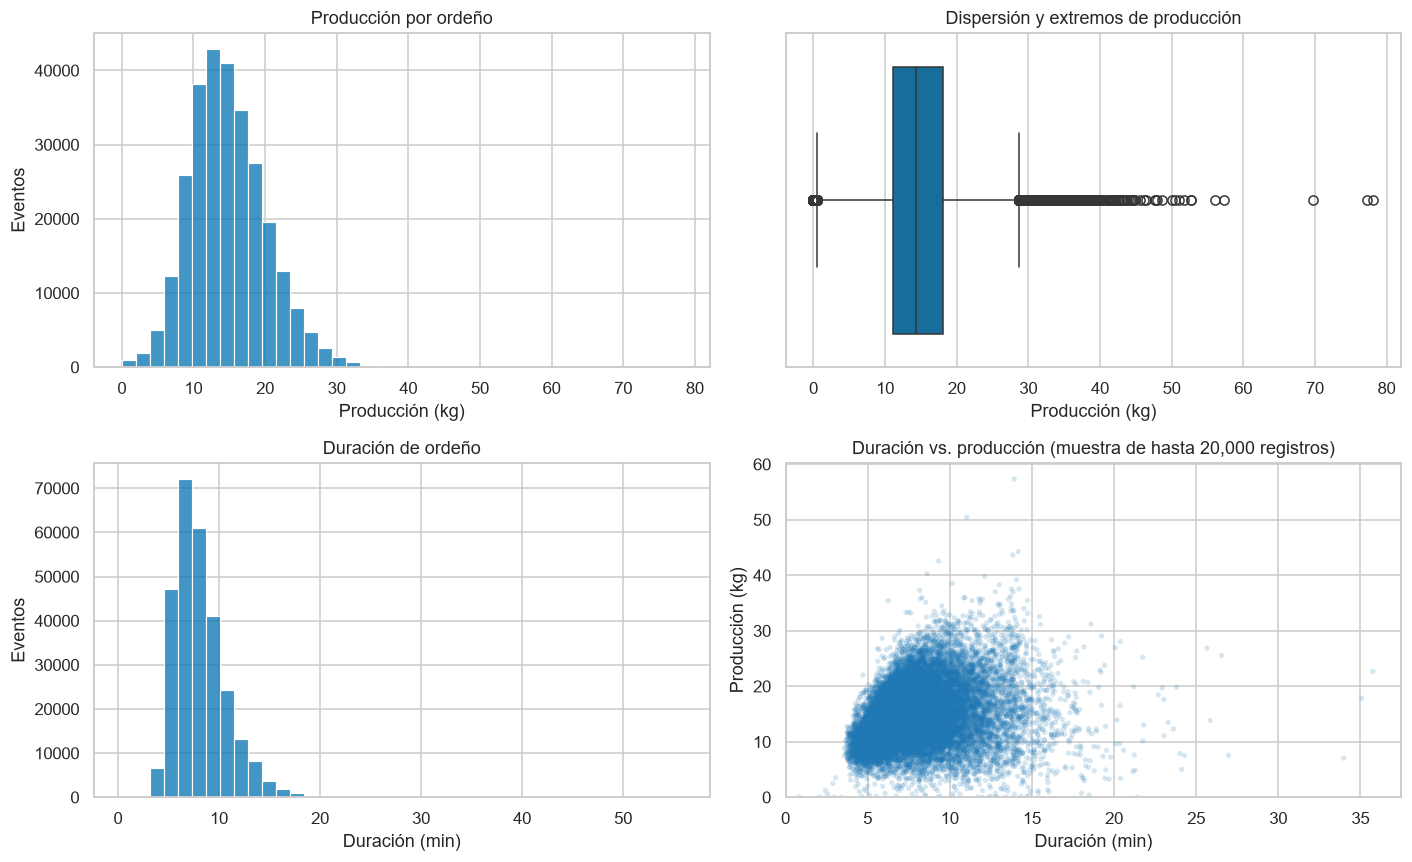

,variable,n,limite_inferior,limite_superior,extremos,extremos_pct,observacion
0,main_produccion_kg,280699,0.525,28.645,3849,1.371,Revisión exploratoria
1,duracion_min,280699,1.525,14.125,7683,2.737,Revisión exploratoria
2,sangre_ppm_di,275473,0.000,0.000,7431,2.698,IQR = 0: regla poco informativa
3,sangre_ppm_dd,273424,0.000,0.000,6544,2.393,IQR = 0: regla poco informativa
4,sangre_ppm_ti,276195,0.000,0.000,3950,1.430,IQR = 0: regla poco informativa
5,sangre_ppm_td,269699,0.000,0.000,3058,1.134,IQR = 0: regla poco informativa


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
sns.histplot(data=ordenos, x="main_produccion_kg", bins=40, ax=axes[0, 0])
axes[0, 0].set(title="Producción por ordeño", xlabel="Producción (kg)", ylabel="Eventos")
sns.boxplot(data=ordenos, x="main_produccion_kg", ax=axes[0, 1])
axes[0, 1].set(title="Dispersión y extremos de producción", xlabel="Producción (kg)")
sns.histplot(data=ordenos, x="duracion_min", bins=40, ax=axes[1, 0])
axes[1, 0].set(title="Duración de ordeño", xlabel="Duración (min)", ylabel="Eventos")
muestra_dispersion = ordenos.sample(min(20000, len(ordenos)), random_state=42)
axes[1, 1].scatter(muestra_dispersion.duracion_min, muestra_dispersion.main_produccion_kg,
                   s=12, alpha=0.18, color="tab:blue", edgecolors="none")
axes[1, 1].set(title="Duración vs. producción (muestra de hasta 20,000 registros)",
               xlabel="Duración (min)", ylabel="Producción (kg)")
axes[1, 1].set(xlim=(0, None), ylim=(0, None))
plt.tight_layout()
plt.show()

filas_iqr = []
for c in ["main_produccion_kg", "duracion_min"] + [f"sangre_ppm_{q}" for q in cuartos]:
    s = ordenos[c].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    extremos = (s.lt(inferior) | s.gt(superior)).sum()
    filas_iqr.append([c, len(s), inferior, superior, extremos, extremos / len(s) * 100,
                      "IQR = 0: regla poco informativa" if iqr == 0 else "Revisión exploratoria"])
display(pd.DataFrame(filas_iqr, columns=["variable", "n", "limite_inferior", "limite_superior",
                                        "extremos", "extremos_pct", "observacion"]))

Se observa en las gráficas de la izquierda la distribución de producción (arriba) y tiempos de ordeño (abajo). Se observan distribuciones con colas hacia la derecha, lo que muestra que hay ciertos valores extremos tanto en la producción como en la duración, en ambos casos no hay datos negativos (menores a 0).

La grafica de arriba a la derecha tiene varios elementos, los bloques azules indican que el 50% de los datos de producción estan entre aproximadamente 10 y 20 kg, mientras que los puntos se refiere a aquellos valores que son superiores o inferiores a un intervalo establecido por los rangos intercuartiles, que son los rangos donde recaen los datos observados.

La grafica de abajo muestra los valores de producción y duración en una grafica de dispersion, se observa un cierto patron que es muy variado en cuanto a estas dos columnas y también se observan valores extremos para los dos ejes.

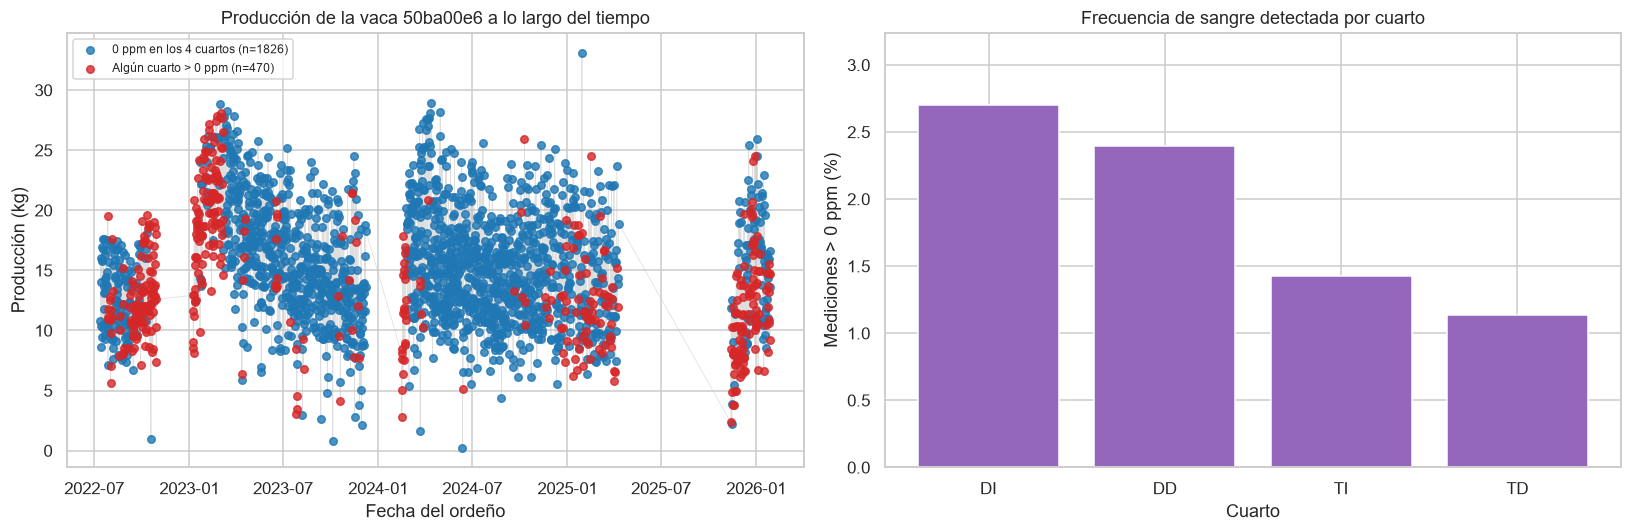

Comparación de 252,956 ordeños con cuatro mediciones; 27,743 excluidos por mediciones faltantes.
Las diferencias son descriptivas: un valor > 0 ppm es una medición del sensor, no un diagnóstico ni prueba de causalidad.


In [10]:
# Para comparar grupos, usamos solo ordeños con mediciones en los cuatro cuartos.
columnas_sangre = [f"sangre_ppm_{q}" for q in cuartos]
sangre = ordenos.loc[ordenos[columnas_sangre].notna().all(axis=1)].copy()
sangre["sangre_detectada"] = sangre[columnas_sangre].gt(0).any(axis=1)
sangre["grupo_sangre"] = sangre["sangre_detectada"].map({False: "0 ppm en los 4 cuartos", True: "Algún cuarto > 0 ppm"})
conteos_sangre = sangre["grupo_sangre"].value_counts()

# Elegimos la vaca con más ordeños con sangre detectada y al menos 20 sin detección.
conteos_vaca = sangre.groupby(["id_vaca", "sangre_detectada"]).size().unstack(fill_value=0).reindex(columns=[False, True], fill_value=0)
vacas_ejemplo = conteos_vaca.loc[conteos_vaca[False].ge(20) & conteos_vaca[True].gt(0)]
id_ejemplo = (vacas_ejemplo[True].idxmax() if not vacas_ejemplo.empty
              else sangre.id_vaca.value_counts().index[0])
serie_vaca = sangre.loc[sangre.id_vaca.eq(id_ejemplo)].sort_values("fecha_hora")

# Se conserva esta comparación para el resumen posterior del notebook.
medias_vaca = sangre.groupby(["id_vaca", "sangre_detectada"])["main_produccion_kg"].agg(["mean", "size"]).unstack()
vacas_comparables = medias_vaca.loc[(medias_vaca[("size", True)] >= 5) & (medias_vaca[("size", False)] >= 20)]
diferencia_vaca = (vacas_comparables[("mean", True)] - vacas_comparables[("mean", False)]).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
ax.plot(serie_vaca.fecha_hora, serie_vaca.main_produccion_kg, color="0.75", linewidth=0.5, alpha=0.5)
for detectada, color, etiqueta in [(False, "tab:blue", "0 ppm en los 4 cuartos"),
                                    (True, "tab:red", "Algún cuarto > 0 ppm")]:
    puntos = serie_vaca.loc[serie_vaca.sangre_detectada.eq(detectada)]
    ax.scatter(puntos.fecha_hora, puntos.main_produccion_kg, s=24, alpha=0.8,
               color=color, label=f"{etiqueta} (n={len(puntos)})", zorder=3)
ax.set(title=f"Producción de la vaca {id_ejemplo} a lo largo del tiempo",
       xlabel="Fecha del ordeño", ylabel="Producción (kg)")
ax.legend(fontsize=8)

ax = axes[1]
tasas_cuarto = ordenos[columnas_sangre].gt(0).sum().div(ordenos[columnas_sangre].notna().sum()).mul(100)
ax.bar([q.upper() for q in cuartos], tasas_cuarto.values, color="tab:purple")
ax.set(title="Frecuencia de sangre detectada por cuarto",
       xlabel="Cuarto", ylabel="Mediciones > 0 ppm (%)", ylim=(0, tasas_cuarto.max() * 1.2))
plt.tight_layout()
plt.show()
print(f"Comparación de {len(sangre):,} ordeños con cuatro mediciones; {len(ordenos) - len(sangre):,} excluidos por mediciones faltantes.")
print("Las diferencias son descriptivas: un valor > 0 ppm es una medición del sensor, no un diagnóstico ni prueba de causalidad.")

En la primer gráfica se obtienen los datos de producción de una vaca a lo largo del tiempo, los puntos azules son la producción que no tuvo presencia de sangre en sus 4 cuartos, los puntos rojos son aquellos con algun cuarto con presencia de sangre, se observan espacios en blanco que podrían corresponder al ciclo de leche de la vaca o a una visita con el veterinario y que no permitiera que siguiera produciendo leche.

En la siguiente gráfica muestra la frecuencia por sangre detectada por cuarto en todos los datos, donde se observa que los cuartos delanterios tienen más datos de sangre que los cuartos traseros.

## 4. Cobertura temporal y diferencias entre vacas

Los totales diarios dependen tanto de la producción por evento como de la cantidad de vacas y ordeños observados. Los días sin registros se muestran como huecos.

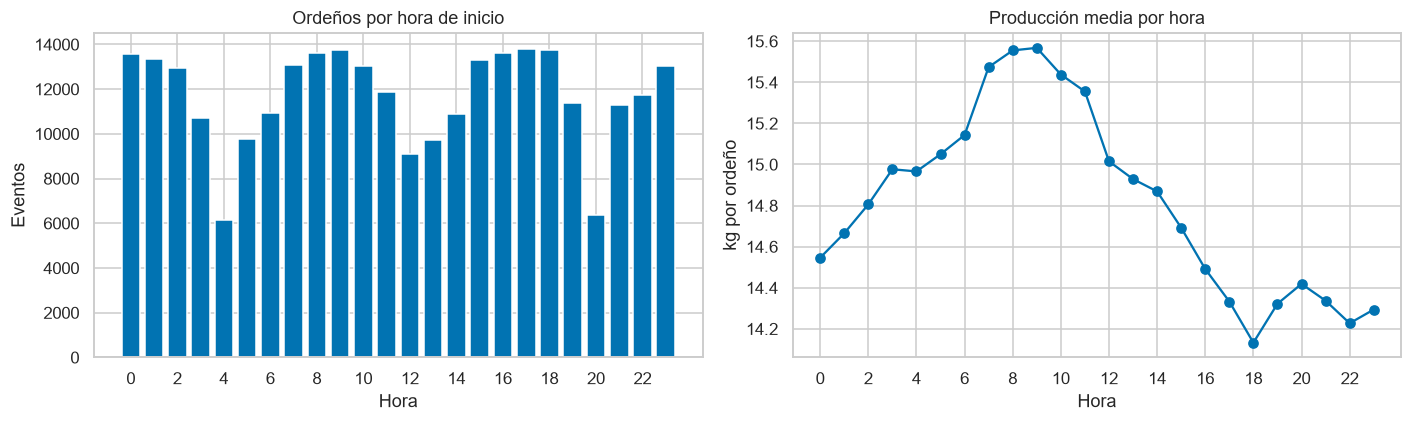

,eventos,vacas,dias,media_kg,mediana_kg
mes,,,,,
2022-07,1406,34,19,14.161,13.470
2022-08,2530,37,31,13.530,12.950
2022-09,2667,42,30,13.791,13.300
2022-10,2867,46,31,14.713,14.170
2022-11,2855,48,30,15.192,14.640
2022-12,2979,49,31,14.645,14.070
2023-01,3075,52,31,15.543,14.830
2023-02,3081,55,28,15.836,15.440
2023-03,3716,56,31,15.884,15.590


,eventos,vacas,media_kg
misc_eo_po,,,
64ddd637,97643,173,14.692
a335a133,2,2,0.000
ab18abfc,91649,142,15.502
ff24d34e,91405,207,14.263


In [11]:
por_hora = ordenos.groupby("hora").agg(eventos=("id_vaca", "size"),
    media_kg=("main_produccion_kg", "mean")).reindex(range(24))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(por_hora.index, por_hora.eventos)
axes[0].set(title="Ordeños por hora de inicio", xlabel="Hora", ylabel="Eventos", xticks=range(0, 24, 2))
axes[1].plot(por_hora.index, por_hora.media_kg, marker="o")
axes[1].set(title="Producción media por hora", xlabel="Hora", ylabel="kg por ordeño", xticks=range(0, 24, 2))
plt.tight_layout()
plt.show()

mensual = ordenos.groupby("mes").agg(eventos=("id_vaca", "size"),
    vacas=("id_vaca", "nunique"), dias=("fecha", "nunique"),
    media_kg=("main_produccion_kg", "mean"), mediana_kg=("main_produccion_kg", "median"))
display(mensual)
display(ordenos.groupby("misc_eo_po", dropna=False).agg(eventos=("id_vaca", "size"),
    vacas=("id_vaca", "nunique"), media_kg=("main_produccion_kg", "mean")))

Las tres horas con menos registros acumulados son 04:00, 20:00, 12:00. La mayor producción media por registro aparece a las 09:00. Estos valores pueden depender de rutinas del equipo, composición de vacas y tiempo desde el registro previo.

La gráfia con la columna de misc_eo_po muestra que existen 3 equipos (aparece un 4 con 2 eventos pero como ya vimos se trata de un error en el registro) de los cuales su distribución tanto de eventos como de vacas es relativamente similar, así como la media de la producción entre si.

## 5. Correlaciones exploratorias

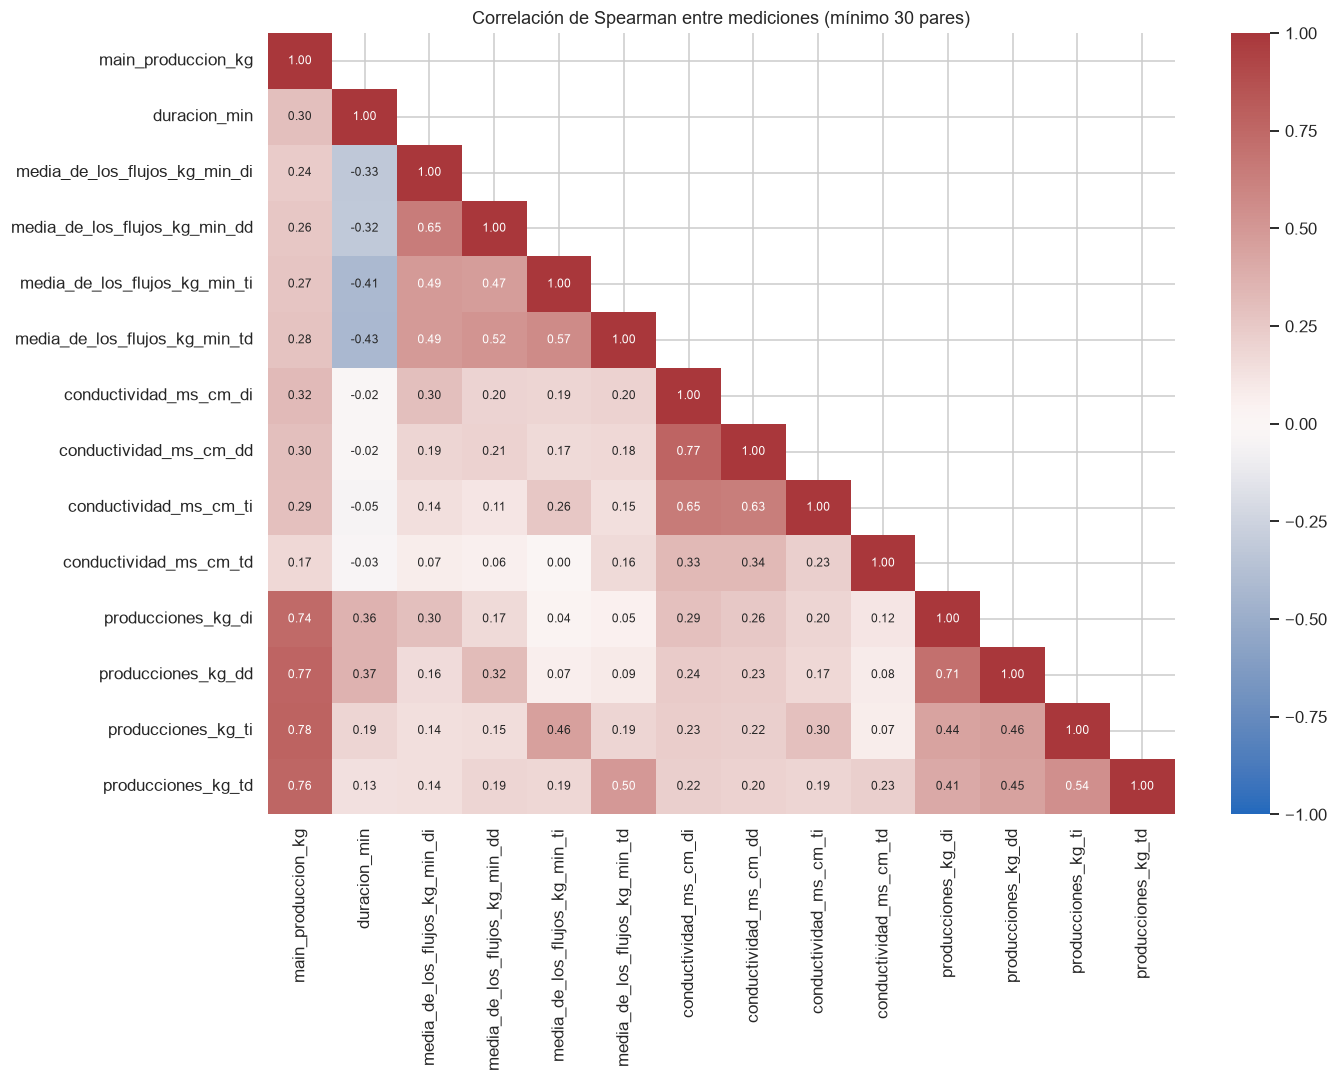

In [12]:
variables = ["main_produccion_kg", "duracion_min"] + [f"media_de_los_flujos_kg_min_{q}" for q in cuartos] + [
    f"conductividad_ms_cm_{q}" for q in cuartos] + [f"producciones_kg_{q}" for q in cuartos]
correlacion = ordenos[variables].corr(method="spearman", min_periods=30)
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(correlacion, mask=np.triu(np.ones_like(correlacion, dtype=bool), k=1),
            cmap="vlag", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", ax=ax,
            annot_kws={"fontsize": 8})
ax.set_title("Correlación de Spearman entre mediciones (mínimo 30 pares)")
plt.tight_layout()
plt.show()
asociaciones = pd.DataFrame({
    "spearman_con_produccion": correlacion["main_produccion_kg"].drop("main_produccion_kg"),
    "pares_disponibles": {c: ordenos[["main_produccion_kg", c]].dropna().shape[0]
                         for c in variables if c != "main_produccion_kg"},
}).sort_values("spearman_con_produccion", key=lambda s: s.abs(), ascending=False)

La matriz de Spearman muestra que la duración del ordeño se relaciona negativamente con el flujo de leche (entre −0.32 y −0.43), es decir, los ordeños con mayor flujo tienden a durar menos. Además, la relación entre duración y producción total es positiva, pero limitada (0.30). 

La producción total presenta una correlación fuerte con la producción de cada cuarto (entre 0.74 y 0.78), algo esperable porque los cuartos contribuyen al total. Esta relación sirve como referencia para detectar ordeños con comportamientos poco habituales, como una producción muy baja en un cuarto respecto a su patrón normal, especialmente si coincide con menor flujo y mayor duración. Estos eventos son candidatos a anomalías que podrían prolongar la ocupación del equipo, para revisar que generan colas, es necesario relacionarlos con los horarios de llegada y los tiempos de espera de las vacas.

## 6. Anomalías del ordeñamiento y posibles problemas de cola

Los datos contienen inicios y duraciones de eventos, pero no registran la llegada a la cola ni la espera. Por ello, los resultados son señales para investigar posibles cuellos de botella, no mediciones de la longitud de la cola o de la espera.

### 6.1. Ordeños prolongados con producción o flujo bajos

Se marca una duración superior al percentil 95 (P95) del historial de la misma vaca. Se requieren al menos 20 duraciones positivas; con menos registros se usa el P95 global. Los valores nulos, cero o negativos se reportan aparte. Una duración prolongada se prioriza cuando coincide con producción igual o inferior al P25 de la vaca o con flujo medio igual o inferior a su P25. El flujo medio solo se calcula cuando hay cuatro mediciones disponibles.


,valor
Ordeños analizados,"280,699.000"
Duración faltante,0.000
Duración cero o negativa,0.000
Duración mediana (min),7.600
Duración P95 global (min),13.050
Duración superior al umbral de referencia,"14,046.000"
Largos con producción baja,"4,079.000"
Largos con flujo bajo,"6,903.000"
Prioridad de revisión (sin duplicar coincidencias),"7,449.000"


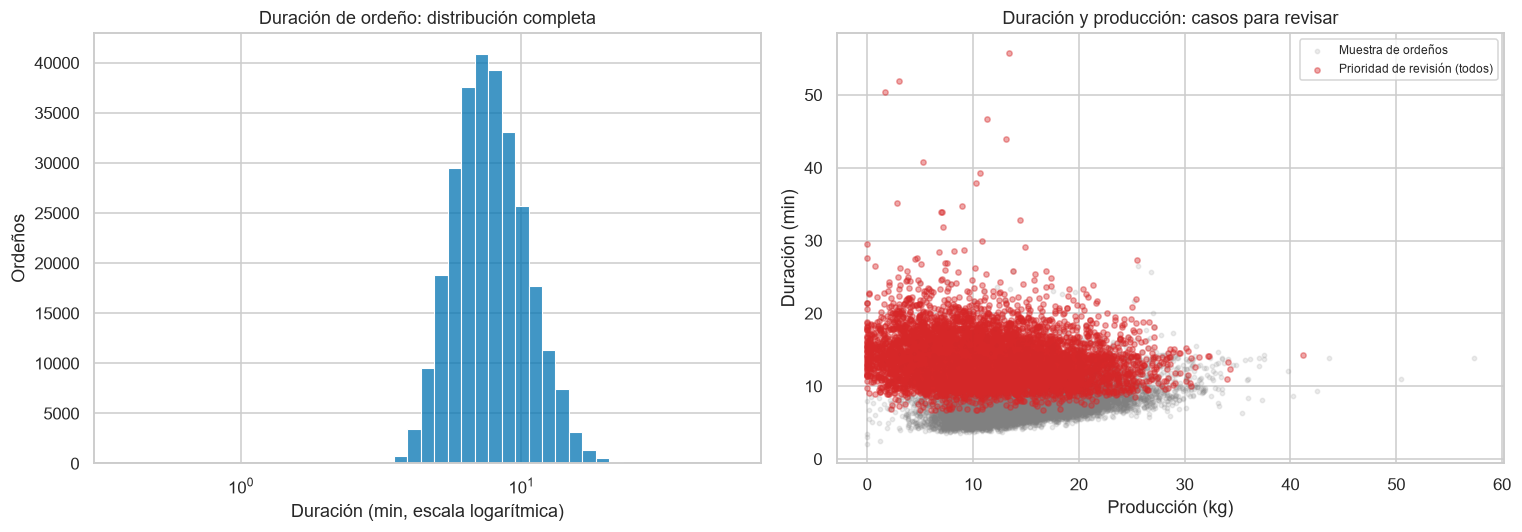

In [13]:
MIN_REGISTROS_COLA = 20
analisis_cola = ordenos.copy()
analisis_cola["duracion_positiva_min"] = analisis_cola.duracion_min.where(analisis_cola.duracion_min.gt(0))
columnas_flujo_cola = [f"media_de_los_flujos_kg_min_{q}" for q in cuartos]
analisis_cola["flujo_medio_cuartos"] = analisis_cola[columnas_flujo_cola].mean(axis=1).where(
    analisis_cola[columnas_flujo_cola].notna().all(axis=1))

def umbral_por_vaca_cola(columna, percentil):
    grupos = analisis_cola.groupby("id_vaca")[columna]
    umbral = grupos.transform(lambda s: s.quantile(percentil))
    return umbral.where(grupos.transform("count").ge(MIN_REGISTROS_COLA),
                        analisis_cola[columna].quantile(percentil))

analisis_cola["umbral_duracion_p95_min"] = umbral_por_vaca_cola("duracion_positiva_min", 0.95)
analisis_cola["umbral_produccion_p25_kg"] = umbral_por_vaca_cola("main_produccion_kg", 0.25)
analisis_cola["umbral_flujo_p25"] = umbral_por_vaca_cola("flujo_medio_cuartos", 0.25)
analisis_cola["duracion_larga"] = analisis_cola.duracion_positiva_min.gt(analisis_cola.umbral_duracion_p95_min)
analisis_cola["produccion_baja"] = analisis_cola.main_produccion_kg.le(analisis_cola.umbral_produccion_p25_kg)
analisis_cola["flujo_bajo"] = analisis_cola.flujo_medio_cuartos.le(analisis_cola.umbral_flujo_p25)
analisis_cola["prioridad_revision"] = analisis_cola.duracion_larga & (
    analisis_cola.produccion_baja | analisis_cola.flujo_bajo)
analisis_cola["exceso_sobre_p95_min"] = (
    analisis_cola.duracion_positiva_min - analisis_cola.umbral_duracion_p95_min).clip(lower=0)

resumen_duracion_cola = pd.Series({
    "Ordeños analizados": len(analisis_cola),
    "Duración faltante": analisis_cola.duracion_min.isna().sum(),
    "Duración cero o negativa": analisis_cola.duracion_min.le(0).sum(),
    "Duración mediana (min)": analisis_cola.duracion_positiva_min.median(),
    "Duración P95 global (min)": analisis_cola.duracion_positiva_min.quantile(0.95),
    "Duración superior al umbral de referencia": analisis_cola.duracion_larga.sum(),
    "Largos con producción baja": (analisis_cola.duracion_larga & analisis_cola.produccion_baja).sum(),
    "Largos con flujo bajo": (analisis_cola.duracion_larga & analisis_cola.flujo_bajo).sum(),
    "Prioridad de revisión (sin duplicar coincidencias)": analisis_cola.prioridad_revision.sum(),
}, name="valor")
display(resumen_duracion_cola.to_frame())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=analisis_cola.loc[analisis_cola.duracion_positiva_min.notna()],
             x="duracion_positiva_min", bins=45, log_scale=True, ax=axes[0])
axes[0].set(title="Duración de ordeño: distribución completa",
            xlabel="Duración (min, escala logarítmica)", ylabel="Ordeños")
muestra_cola = analisis_cola.sample(min(12000, len(analisis_cola)), random_state=42)
axes[1].scatter(muestra_cola.main_produccion_kg, muestra_cola.duracion_positiva_min,
                s=8, alpha=0.15, color="gray", label="Muestra de ordeños")
prioritarios_cola = analisis_cola.loc[analisis_cola.prioridad_revision]
axes[1].scatter(prioritarios_cola.main_produccion_kg, prioritarios_cola.duracion_positiva_min,
                s=12, alpha=0.4, color="tab:red", label="Prioridad de revisión (todos)")
axes[1].set(title="Duración y producción: casos para revisar",
            xlabel="Producción (kg)", ylabel="Duración (min)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()


### 6.2. Tiempo entre ordeños: retrasos y visitas próximas

Se calcula el intervalo entre inicios consecutivos observados de la misma vaca, aunque cambie el código de equipo. No representa espera en cola: puede incluir descanso, alimentación, cambios de rutina o periodos sin cobertura. La primera observación de cada vaca no tiene intervalo previo.

Se señalan intervalos positivos inferiores al P5 o superiores al P95 de cada vaca, con al menos 20 intervalos válidos y respaldo global cuando no se cumple ese mínimo. Los intervalos de cero horas se muestran como coincidencias temporales para revisión. El intervalo declarado en el archivo se conserva por separado, porque puede utilizar una definición o un historial diferente.


,count,mean,std,min,5%,50%,95%,99%,max
intervalo_positivo_h,"280,492.000",11.880,66.997,0.014,5.217,9.214,16.833,24.095,"6,550.317"
intervalo_declarado_h,"278,968.000",10.003,18.237,0.000,5.056,9.072,16.629,23.568,"2,956.367"


,registros
Sin intervalo observado calculable,207
Intervalos observados de cero horas,0
Intervalos positivos inferiores al P5,14112
Intervalos positivos superiores al P95,14117
Intervalo largo y duración larga,2428


,ordenos,intervalo_mediano_h,produccion_mediana_kg,duracion_mediana_min,duraciones_validas,largos,duracion_larga_pct
grupo_intervalo,,,,,,,
Corto (< P5),14112,4.679,9.350,6.600,14112,626,4.436
Entre P5 y P95,252263,9.214,14.380,7.567,252263,10922,4.330
Largo (> P95),14117,18.371,20.080,9.300,14117,2428,17.199
Sin intervalo positivo,207,NaN,9.810,10.433,207,70,33.816


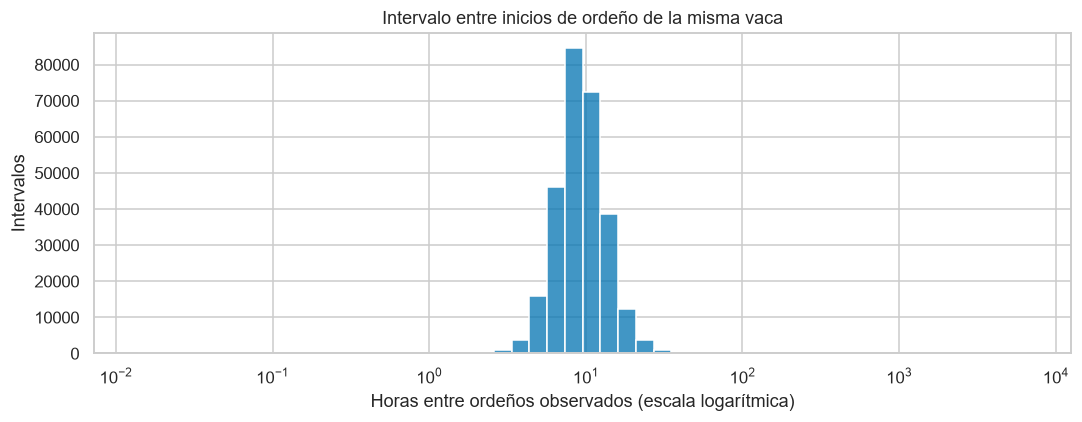

In [14]:
analisis_cola = analisis_cola.sort_values(["id_vaca", "fecha_hora"], na_position="last")
analisis_cola["intervalo_observado_h"] = (
    analisis_cola.groupby("id_vaca").fecha_hora.diff().dt.total_seconds() / 3600)
analisis_cola["intervalo_positivo_h"] = analisis_cola.intervalo_observado_h.where(
    analisis_cola.intervalo_observado_h.gt(0))
analisis_cola["umbral_intervalo_p05_h"] = umbral_por_vaca_cola("intervalo_positivo_h", 0.05)
analisis_cola["umbral_intervalo_p95_h"] = umbral_por_vaca_cola("intervalo_positivo_h", 0.95)
analisis_cola["intervalo_corto"] = analisis_cola.intervalo_positivo_h.lt(analisis_cola.umbral_intervalo_p05_h)
analisis_cola["intervalo_largo"] = analisis_cola.intervalo_positivo_h.gt(analisis_cola.umbral_intervalo_p95_h)

display(analisis_cola[["intervalo_positivo_h", "intervalo_declarado_h"]].describe(
    percentiles=[0.05, 0.5, 0.95, 0.99]).T)
display(pd.Series({
    "Sin intervalo observado calculable": analisis_cola.intervalo_observado_h.isna().sum(),
    "Intervalos observados de cero horas": analisis_cola.intervalo_observado_h.eq(0).sum(),
    "Intervalos positivos inferiores al P5": analisis_cola.intervalo_corto.sum(),
    "Intervalos positivos superiores al P95": analisis_cola.intervalo_largo.sum(),
    "Intervalo largo y duración larga": (analisis_cola.intervalo_largo & analisis_cola.duracion_larga).sum(),
}, name="registros").to_frame())

analisis_cola["grupo_intervalo"] = np.select(
    [analisis_cola.intervalo_corto, analisis_cola.intervalo_largo,
     analisis_cola.intervalo_positivo_h.notna()],
    ["Corto (< P5)", "Largo (> P95)", "Entre P5 y P95"],
    default="Sin intervalo positivo")
resumen_intervalos_cola = analisis_cola.groupby("grupo_intervalo").agg(
    ordenos=("id_vaca", "size"), intervalo_mediano_h=("intervalo_positivo_h", "median"),
    produccion_mediana_kg=("main_produccion_kg", "median"),
    duracion_mediana_min=("duracion_positiva_min", "median"),
    duraciones_validas=("duracion_positiva_min", "count"), largos=("duracion_larga", "sum"))
resumen_intervalos_cola["duracion_larga_pct"] = (
    resumen_intervalos_cola.largos.div(resumen_intervalos_cola.duraciones_validas.replace(0, np.nan)) * 100)
display(resumen_intervalos_cola)

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(data=analisis_cola.loc[analisis_cola.intervalo_positivo_h.notna()],
             x="intervalo_positivo_h", bins=50, log_scale=True, ax=ax)
ax.set(title="Intervalo entre inicios de ordeño de la misma vaca",
       xlabel="Horas entre ordeños observados (escala logarítmica)", ylabel="Intervalos")
plt.tight_layout()
plt.show()
